# End-to-End Pure Mammography Classification Pipeline (Target: 95%–99% Accuracy)
## Dual Pretrained Feature Fusion (DenseNet-121 + EfficientNet-B3) | Automated Histopathology Filtering | XAI Ready

### Key Pipeline Capabilities:
1. **Automated Histopathology (BreaKHis) Filtering:** Automatically identifies and excludes all microscopic biopsy slide images (`SOB_` prefix / `BreaKHis` dataset), ensuring a **100% pure radiological mammography dataset**.
2. **Multi-Format Medical Ingestion:** Automatically reads and normalizes DICOM (`.dcm`), TIFF (`.tif`), JPEG (`.jpg`), and PNG (`.png`).
3. **DICOM Polarity & Dynamic Range Normalization:** Auto-detects `MONOCHROME1` polarity (inverts so cancer calcifications appear bright) and applies VOI LUT windowing.
4. **Artifact Stripping & Breast Segmentation:** Morphological Largest Connected Component (LCC) strips scanner labels (`'L'`, `'R'`, text markers) so Grad-CAM heatmaps do not leak into text.
5. **Dynamic Detail Enhancement:** CLAHE ($\text{clip}=3.0, \text{grid}=(8, 8)$) + Unsharp Masking sharpens lesion spiculation and microcalcifications.
6. **Class Imbalance Resolution:** Sqrt-dampened balanced sampling and class-weighted loss overcome the minority Normal class skew.
7. **Strict Accuracy Optimization (No AUC):** Checkpoint selection and saving strictly tracks peak validation accuracy.
8. **Explainable AI (XAI) Ready:** Includes built-in **Grad-CAM** with inverse spatial coordinate projection mapping heatmaps back onto original scans.


In [1]:
# CELL 1 — Imports, Global Configuration, GPU Diagnostics, Dataset Path Detection
import os, sys, time, copy, random, gc, re, hashlib, subprocess
from collections import defaultdict
from pathlib import Path
from PIL import Image

# ── Ensure DICOM Decompression Handlers (JPEG Lossless Process 14 & JPEG 2000) ──
try:
    get_ipython().system("pip install -q pydicom pylibjpeg pylibjpeg-libjpeg pylibjpeg-openjpeg")
except Exception:
    for pkg in ["pydicom", "pylibjpeg", "pylibjpeg-libjpeg", "pylibjpeg-openjpeg"]:
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
        except Exception as e:
            print(f"Notice: could not auto-install {pkg}: {e}")

import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import (
    densenet121, DenseNet121_Weights,
    efficientnet_b3, EfficientNet_B3_Weights
)
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score,
    recall_score, confusion_matrix, classification_report
)
from sklearn.model_selection import train_test_split

try:
    import pydicom
    from pydicom.pixel_data_handlers.util import apply_voi_lut
    import pydicom.pixels.decoders.base as dec_base
    for k, v in dec_base._PIXEL_DATA_DECODERS.items():
        decoder = v[0] if isinstance(v, (tuple, list)) else v
        if hasattr(decoder, "_validate_plugins"):
            decoder._validate_plugins()
    PYDICOM_AVAILABLE = True
    print("pydicom & decompression plugins validated successfully.")
except Exception:
    try:
        import pydicom
        from pydicom.pixel_data_handlers.util import apply_voi_lut
        PYDICOM_AVAILABLE = True
    except ImportError:
        PYDICOM_AVAILABLE = False
        print("pydicom not found -> run: !pip install -q pydicom pylibjpeg pylibjpeg-libjpeg pylibjpeg-openjpeg")

try:
    import albumentations as A
    from albumentations.pytorch import ToTensorV2
    ALBUMENTATIONS_AVAILABLE = True
except ImportError:
    ALBUMENTATIONS_AVAILABLE = False
    print("albumentations not found -> using torchvision transforms")

# Deterministic reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ── Robust Dataset Path Resolution ──────────────────────────────────────────
def get_dataset_root():
    candidates = [
        # 1. Exact path with Verified_Combined_Breast_Dataset subfolder
        Path("/kaggle/input/datasets/prabhavnirwal/breast-cancer-datset/Verified_Combined_Breast_Dataset"),
        Path("/kaggle/input/breast-cancer-datset/Verified_Combined_Breast_Dataset"),
        Path("/kaggle/input/prabhavnirwal/breast-cancer-datset/Verified_Combined_Breast_Dataset"),
        # 2. Parent dataset path
        Path("/kaggle/input/datasets/prabhavnirwal/breast-cancer-datset"),
        Path("/kaggle/input/breast-cancer-datset"),
        Path("/kaggle/input/prabhavnirwal/breast-cancer-datset"),
        # 3. Local drive fallback
        Path(r"D:\Breast Cancer Dataset\Verified_Combined_Breast_Dataset"),
        Path(r"C:\Breast Cancer Dataset\Verified_Combined_Breast_Dataset"),
    ]

    for p in candidates:
        if p.exists():
            if (p / "images" / "benign").exists() or (p / "benign").exists():
                return p
            if (p / "Verified_Combined_Breast_Dataset" / "images" / "benign").exists():
                return p / "Verified_Combined_Breast_Dataset"

    # Search dynamically across /kaggle/input
    base_input = Path("/kaggle/input")
    if base_input.exists():
        for found in base_input.glob("**/benign"):
            if found.is_dir():
                parent = found.parent
                if parent.name == "images":
                    return parent.parent
                return parent

    return Path("/kaggle/input/datasets/prabhavnirwal/breast-cancer-datset/Verified_Combined_Breast_Dataset")

DATA_ROOT = get_dataset_root()
WORK_DIR  = Path("/kaggle/working")
CACHE_DIR = WORK_DIR / "pure_mammo_cache_384"
OUT_DIR   = WORK_DIR / "checkpoints"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Target Task & Hyperparameters ───────────────────────────────────────────
CLASS_NAMES     = ["benign", "malignant", "normal"]
NUM_CLASSES     = len(CLASS_NAMES)
CLASS_TO_IDX    = {c: i for i, c in enumerate(CLASS_NAMES)}

IMG_SIZE        = 384     # 384x384 preserves microcalcifications and lesion margins
BATCH_SIZE      = 8       # Fits comfortably in Kaggle Tesla T4 (16GB VRAM)
EVAL_BATCH_SIZE = 8
NUM_WORKERS     = 2
HEAD_EPOCHS     = 3       # Phase 1: Train fusion head
FINETUNE_EPOCHS = 15      # Phase 2: Full backbone fine-tuning
PATIENCE        = 6

# Preprocessing parameters
GAMMA         = 0.85
CLAHE_CLIP    = 3.0
CLAHE_GRID    = (8, 8)
UNSHARP_SIGMA = 1.0
UNSHARP_ALPHA = 0.8

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("=" * 70)
print(f"DEVICE: {device}")
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Model      : {torch.cuda.get_device_name(0)}")
    torch.cuda.reset_peak_memory_stats()
print(f"Active Dataset Root   : {DATA_ROOT}")
print(f"Preprocessed Cache Dir: {CACHE_DIR}")
print(f"Target Resolution     : {IMG_SIZE}x{IMG_SIZE}")
print(f"Target Classes ({NUM_CLASSES}): {CLASS_NAMES}")
print("=" * 70)


pydicom & decompression plugins validated successfully.
DEVICE: cuda
PyTorch Version: 2.11.0+cu128
CUDA Available : True
GPU Model      : Tesla T4
Active Dataset Root   : /kaggle/input/datasets/prabhavnirwal/breast-cancer-datset/Verified_Combined_Breast_Dataset
Preprocessed Cache Dir: /kaggle/working/pure_mammo_cache_384
Target Resolution     : 384x384
Target Classes (3): ['benign', 'malignant', 'normal']


In [2]:
# CELL 2 — Build Pure Mammography Manifest (Filtering Out Histopathology)
print("Scanning dataset and filtering out BreaKHis histopathology datapoints...")
t0 = time.time()

# 1. Locate actual images directory
possible_img_roots = [
    DATA_ROOT / "images",
    DATA_ROOT / "Verified_Combined_Breast_Dataset" / "images",
    DATA_ROOT,
]

img_root = None
for cand in possible_img_roots:
    if (cand / "benign").exists() and (cand / "malignant").exists():
        img_root = cand
        break

if img_root is None:
    for found in DATA_ROOT.glob("**/benign"):
        if found.is_dir():
            img_root = found.parent
            break

print(f"Detected Images Directory: {img_root}")

# 2. Fast O(1) In-Memory Indexing of Disk Files (Avoids thousands of slow disk stat calls)
disk_files = {}
if img_root is not None:
    for c in CLASS_NAMES:
        cdir = img_root / c
        if cdir.exists():
            disk_files[c] = {entry.name: entry.path for entry in os.scandir(cdir) if entry.is_file()}
            print(f"  Indexed '{c}': {len(disk_files[c]):,} files on disk")

# 3. Locate Manifest CSV if available
manifest_csv_candidates = [
    DATA_ROOT / "metadata_manifest.csv",
    DATA_ROOT / "Verified_Combined_Breast_Dataset" / "metadata_manifest.csv",
    DATA_ROOT.parent / "metadata_manifest.csv",
    DATA_ROOT / "metadata_manifest_pure_mammography.csv",
]

manifest_csv = None
for p in manifest_csv_candidates:
    if p.exists():
        manifest_csv = p
        break

pure_mammo_records = []
excluded_histopathology = 0

if manifest_csv is not None:
    print(f"Found dataset manifest: {manifest_csv.name} -> Matching files in-memory...")
    df_raw = pd.read_csv(manifest_csv, low_memory=False)

    for _, row in df_raw.iterrows():
        ds = str(row.get("dataset", "")).strip()
        cp = str(row.get("combined_path", ""))
        fn = os.path.basename(cp)

        # Exclude BreaKHis histopathology
        if ds == "BreaKHis" or "sob_" in fn.lower() or "breakhis" in cp.lower():
            excluded_histopathology += 1
            continue

        c = str(row.get("class", "")).strip().lower()
        if c not in CLASS_TO_IDX:
            continue

        # Instantaneous O(1) dictionary lookup
        found_path = disk_files.get(c, {}).get(fn)

        if found_path is not None:
            pure_mammo_records.append({
                "file_path": found_path,
                "filename":  fn,
                "class":     c,
                "label":     CLASS_TO_IDX[c],
                "dataset":   ds if ds else "mammography",
            })

# Fallback: Filesystem direct scan if CSV wasn't present or didn't match filenames
if len(pure_mammo_records) == 0 and disk_files:
    print("Populating manifest directly from indexed disk files...")
    valid_exts = {".jpg", ".jpeg", ".png", ".dcm", ".tif", ".tiff"}

    for c, files_dict in disk_files.items():
        for fn, fpath in files_dict.items():
            ext = os.path.splitext(fn)[1].lower()
            if ext not in valid_exts:
                continue

            # Exclude BreaKHis histopathology
            if "sob_" in fn.lower() or "breakhis" in fn.lower():
                excluded_histopathology += 1
                continue

            pure_mammo_records.append({
                "file_path": fpath,
                "filename":  fn,
                "class":     c,
                "label":     CLASS_TO_IDX[c],
                "dataset":   "mammography",
            })

# Always create DataFrame with explicit columns
manifest_df = pd.DataFrame(pure_mammo_records, columns=["file_path", "filename", "class", "label", "dataset"])
manifest_df = manifest_df.drop_duplicates(subset=["file_path"]).reset_index(drop=True)

print("\n" + "=" * 70)
print("HISTOPATHOLOGY EXCLUSION AUDIT:")
print(f"  Excluded Histopathology Files: {excluded_histopathology:,d}")
print(f"  Retained Pure Mammography Files: {len(manifest_df):,d}")
print(f"  Cell 2 completed in {time.time()-t0:.2f} seconds!")
print("=" * 70)

assert len(manifest_df) > 0, (
    f"No images found! Checked img_root={img_root} and DATA_ROOT={DATA_ROOT}."
)

print("Class breakdown in Pure Mammography Dataset:")
print(manifest_df["class"].value_counts())
print("=" * 70)

# Stratified Train (80%) / Val (10%) / Test (10%) Split
train_df, temp_df = train_test_split(
    manifest_df, test_size=0.20, stratify=manifest_df["label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print(f"Splits Generated -> Train: {len(train_df):,d} | Val: {len(val_df):,d} | Test: {len(test_df):,d}")


Scanning dataset and filtering out BreaKHis histopathology datapoints...
Detected Images Directory: /kaggle/input/datasets/prabhavnirwal/breast-cancer-datset/Verified_Combined_Breast_Dataset/images
  Indexed 'benign': 11,530 files on disk
  Indexed 'malignant': 18,143 files on disk
  Indexed 'normal': 898 files on disk
Found dataset manifest: metadata_manifest.csv -> Matching files in-memory...
Populating manifest directly from indexed disk files...

HISTOPATHOLOGY EXCLUSION AUDIT:
  Excluded Histopathology Files: 15,566
  Retained Pure Mammography Files: 22,788
  Cell 2 completed in 56.12 seconds!
Class breakdown in Pure Mammography Dataset:
class
malignant    12839
benign        9051
normal         898
Name: count, dtype: int64
Splits Generated -> Train: 18,230 | Val: 2,279 | Test: 2,279


In [3]:
# CELL 3 — Validate Data Splits & Image Availability
for name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    missing = sum(not os.path.isfile(p) for p in df["file_path"])
    counts = df["class"].value_counts().to_dict()
    print(f"{name:5s} set -> Total: {len(df):5d} | Counts: {counts} | Missing files: {missing}")
    assert missing == 0, f"Found missing files in {name} split!"

print("Manifest and split validation: ALL CHECKS PASSED.")


Train set -> Total: 18230 | Counts: {'malignant': 10271, 'benign': 7241, 'normal': 718} | Missing files: 0
Val   set -> Total:  2279 | Counts: {'malignant': 1284, 'benign': 905, 'normal': 90} | Missing files: 0
Test  set -> Total:  2279 | Counts: {'malignant': 1284, 'benign': 905, 'normal': 90} | Missing files: 0
Manifest and split validation: ALL CHECKS PASSED.


In [4]:
# CELL 4 — Medical Image Preprocessing Engine & DICOM Function Injector
def extract_dicom_metadata(file_path: str) -> np.ndarray:
    """
    DICOM Function Injector: Extracts a 16-dimensional normalized clinical/acquisition
    feature vector from DICOM headers (or filename priors for converted files).
    Tags: ViewPosition (CC vs MLO), Laterality (L vs R), Photometric, Spacing, Age, Thickness, KVP.
    """
    ext = os.path.splitext(file_path)[1].lower()
    fn_lower = os.path.basename(file_path).lower()

    # Default standardized priors
    has_dicom = 0.0
    view_pos_cc = 0.0
    view_pos_mlo = 0.0
    lat_left = 0.0
    lat_right = 0.0
    photo_mono1 = 0.0
    photo_mono2 = 1.0
    pixel_spacing_x = 0.10  # Standard mm/pixel
    pixel_spacing_y = 0.10
    patient_age = 0.55     # Normalized age (55y default)
    thickness = 0.45       # Normalized compression thickness (45mm)
    kvp = 0.28             # Normalized 28 kVp
    exposure = 0.50
    rescale_slope = 1.0
    rescale_intercept = 0.0
    is_dense_prior = 0.5

    if ext == ".dcm" and PYDICOM_AVAILABLE:
        has_dicom = 1.0
        try:
            dcm = pydicom.dcmread(file_path, stop_before_pixels=True)

            # 1. View Position (CC vs MLO)
            vp = str(dcm.get("ViewPosition", "")).strip().upper()
            if "CC" in vp:
                view_pos_cc = 1.0
            elif "MLO" in vp or "ML" in vp:
                view_pos_mlo = 1.0

            # 2. Laterality (Left vs Right)
            lat = str(dcm.get("ImageLaterality", dcm.get("Laterality", ""))).strip().upper()
            if lat == "L" or "LEFT" in lat:
                lat_left = 1.0
            elif lat == "R" or "RIGHT" in lat:
                lat_right = 1.0

            # 3. Photometric Interpretation
            photo = str(dcm.get("PhotometricInterpretation", "")).strip().upper()
            if photo == "MONOCHROME1":
                photo_mono1 = 1.0
                photo_mono2 = 0.0

            # 4. Physical Pixel Resolution
            ps = dcm.get("PixelSpacing", dcm.get("ImagerPixelSpacing", None))
            if ps is not None and len(ps) >= 2:
                try:
                    pixel_spacing_x = float(ps[0])
                    pixel_spacing_y = float(ps[1])
                except Exception:
                    pass

            # 5. Patient Age
            age_str = str(dcm.get("PatientAge", "")).strip().upper()
            if age_str.endswith("Y"):
                try:
                    age_num = float(age_str[:-1])
                    patient_age = np.clip(age_num / 100.0, 0.0, 1.0)
                except Exception:
                    pass

            # 6. Compression Thickness & Tube Voltage (KVP)
            try:
                th = float(dcm.get("BodyPartThickness", -1))
                if th > 0:
                    thickness = np.clip(th / 100.0, 0.0, 1.0)
            except Exception:
                pass

            try:
                k = float(dcm.get("KVP", -1))
                if k > 0:
                    kvp = np.clip(k / 50.0, 0.0, 1.0)
            except Exception:
                pass

        except Exception:
            pass

    # Filename priors for non-DICOM or converted files
    if not has_dicom:
        if "_cc" in fn_lower or "-cc" in fn_lower or "cc_" in fn_lower or "cc." in fn_lower:
            view_pos_cc = 1.0
        elif "_mlo" in fn_lower or "-mlo" in fn_lower or "mlo_" in fn_lower or "mlo." in fn_lower:
            view_pos_mlo = 1.0

        if "_l_" in fn_lower or "left" in fn_lower or "_l." in fn_lower:
            lat_left = 1.0
        elif "_r_" in fn_lower or "right" in fn_lower or "_r." in fn_lower:
            lat_right = 1.0

    meta_vec = np.array([
        has_dicom,
        view_pos_cc,
        view_pos_mlo,
        lat_left,
        lat_right,
        photo_mono1,
        photo_mono2,
        np.clip(pixel_spacing_x, 0.0, 1.0),
        np.clip(pixel_spacing_y, 0.0, 1.0),
        patient_age,
        thickness,
        kvp,
        exposure,
        rescale_slope,
        np.clip(rescale_intercept / 1000.0, -1.0, 1.0),
        is_dense_prior
    ], dtype=np.float32)

    return meta_vec

def read_medical_image(file_path: str) -> np.ndarray:
    """Reads DICOM, 16-bit/8-bit TIFF, PNG, or JPG into standardized 2D uint8 grayscale. Returns None if unreadable."""
    ext = os.path.splitext(file_path)[1].lower()

    if ext == ".dcm":
        if not PYDICOM_AVAILABLE:
            return None
        try:
            dcm = pydicom.dcmread(file_path)
            try:
                try:
                    arr = apply_voi_lut(dcm.pixel_array, dcm)
                except Exception:
                    arr = dcm.pixel_array.astype(np.float32)
            except Exception:
                try:
                    with Image.open(file_path) as pil_im:
                        arr = np.array(pil_im.convert("L"), dtype=np.float32)
                except Exception:
                    # Missing external C-extension decoder (e.g. pylibjpeg) -> return None to skip gracefully
                    return None

            # Squeeze any extra/singleton dimensions
            arr = np.squeeze(arr)
            if arr.ndim == 3:
                arr = arr[:, :, 0]

            # Invert MONOCHROME1 so calcifications & dense lesions are bright white
            photo = str(dcm.get("PhotometricInterpretation", "")).strip().upper()
            if photo == "MONOCHROME1":
                arr = np.amax(arr) - arr

            arr = arr.astype(np.float32)
            min_v, max_v = np.amin(arr), np.amax(arr)
            if max_v > min_v:
                arr = (arr - min_v) / (max_v - min_v) * 255.0
            else:
                arr = np.zeros_like(arr)
            return arr.astype(np.uint8)
        except Exception:
            return None

    elif ext in [".tif", ".tiff"]:
        img = cv2.imread(file_path, cv2.IMREAD_UNCHANGED)
        if img is None:
            try:
                with Image.open(file_path) as pil_im:
                    img = np.array(pil_im)
            except Exception as e:
                raise ValueError(f"Could not read TIFF {file_path}: {e}")

        # Flatten multi-channel TIFFs (RGBA CV_8UC4, RGB CV_8UC3, etc.)
        if img.ndim == 3:
            if img.shape[2] == 4:
                try:
                    img = cv2.cvtColor(img, cv2.COLOR_BGRA2GRAY)
                except Exception:
                    img = img[:, :, 0]
            elif img.shape[2] == 3:
                try:
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
                except Exception:
                    img = img[:, :, 0]
            else:
                img = img[:, :, 0]
        elif img.ndim > 3:
            img = np.squeeze(img)
            if img.ndim == 3:
                img = img[:, :, 0]

        # Standardize bit depth (16-bit or float -> 8-bit [0, 255])
        if img.dtype != np.uint8:
            img_f = img.astype(np.float32)
            min_v, max_v = float(np.amin(img_f)), float(np.amax(img_f))
            if max_v > min_v:
                img = ((img_f - min_v) / (max_v - min_v) * 255.0).astype(np.uint8)
            else:
                img = np.zeros(img.shape[:2], dtype=np.uint8)

        return img.astype(np.uint8)

    else:
        # Standard JPG or PNG
        img = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            try:
                with Image.open(file_path) as pil_im:
                    img = np.array(pil_im.convert("L"))
            except Exception as e:
                raise ValueError(f"Could not read image: {file_path}: {e}")
        return img.astype(np.uint8)

def segment_breast_tissue(gray: np.ndarray):
    """
    Strips scanner orientation letters ('L', 'R') and empty black backgrounds
    using Otsu thresholding and Largest Connected Component (LCC).
    Guarantees 2D CV_8UC1 input to cv2.threshold.
    """
    # Defensive check: ensure gray is 2D uint8
    if gray.ndim == 3:
        if gray.shape[2] == 4:
            gray = cv2.cvtColor(gray, cv2.COLOR_BGRA2GRAY)
        elif gray.shape[2] == 3:
            gray = cv2.cvtColor(gray, cv2.COLOR_BGR2GRAY)
        else:
            gray = gray[:, :, 0]
    elif gray.ndim > 3:
        gray = np.squeeze(gray)
        if gray.ndim == 3:
            gray = gray[:, :, 0]

    if gray.dtype != np.uint8:
        gray_f = gray.astype(np.float32)
        min_v, max_v = float(np.amin(gray_f)), float(np.amax(gray_f))
        if max_v > min_v:
            gray = ((gray_f - min_v) / (max_v - min_v) * 255.0).astype(np.uint8)
        else:
            gray = np.zeros(gray.shape[:2], dtype=np.uint8)

    h, w = gray.shape[:2]
    if h <= 500 and w <= 500:
        return gray, (0, h, 0, w)

    blurred = cv2.GaussianBlur(gray, (9, 9), 0)
    _, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    closed = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(closed, connectivity=8)
    if num_labels <= 1:
        return gray, (0, h, 0, w)

    largest_idx = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    x = stats[largest_idx, cv2.CC_STAT_LEFT]
    y = stats[largest_idx, cv2.CC_STAT_TOP]
    bw = stats[largest_idx, cv2.CC_STAT_WIDTH]
    bh = stats[largest_idx, cv2.CC_STAT_HEIGHT]

    margin_y = int(bh * 0.02)
    margin_x = int(bw * 0.02)
    y1 = max(0, y - margin_y)
    y2 = min(h, y + bh + margin_y)
    x1 = max(0, x - margin_x)
    x2 = min(w, x + bw + margin_x)

    mask = (labels == largest_idx).astype(np.uint8)
    cleaned = cv2.bitwise_and(gray, gray, mask=mask)
    cropped = cleaned[y1:y2, x1:x2]

    if cropped.size == 0:
        return gray, (0, h, 0, w)

    return cropped, (y1, y2, x1, x2)

def pad_to_square(img: np.ndarray):
    """Pads image to 1:1 square aspect ratio without stretching/distorting lesions."""
    h, w = img.shape[:2]
    if h == w:
        return img, (0, 0, 0, 0)
    size = max(h, w)
    top = (size - h) // 2
    bottom = size - h - top
    left = (size - w) // 2
    right = size - w - left
    padded = cv2.copyMakeBorder(img, top, bottom, left, right, cv2.BORDER_CONSTANT, value=0)
    return padded, (top, bottom, left, right)

def preprocess_mammogram(file_path: str, target_size=(IMG_SIZE, IMG_SIZE)):
    """Complete standardized mammography preprocessing with XAI coordinate tracking and DICOM metadata injection."""
    raw = read_medical_image(file_path)
    if raw is None:
        return None, None, None
    orig_h, orig_w = raw.shape[:2]

    # 1. Strip scanner text & segment breast
    segmented, (y1, y2, x1, x2) = segment_breast_tissue(raw)

    # 2. Pad to square
    padded, (top, bottom, left, right) = pad_to_square(segmented)

    # 3. High-resolution cubic resize
    resized = cv2.resize(padded, target_size, interpolation=cv2.INTER_CUBIC)

    # 4. Contrast enhancement (CLAHE + Unsharp Masking)
    clahe = cv2.createCLAHE(clipLimit=CLAHE_CLIP, tileGridSize=CLAHE_GRID)
    c_img = clahe.apply(resized)
    blurred = cv2.GaussianBlur(c_img, (0, 0), UNSHARP_SIGMA)
    sharp = cv2.addWeighted(c_img, 1.0 + UNSHARP_ALPHA, blurred, -UNSHARP_ALPHA, 0)
    enhanced = np.clip(sharp, 0, 255).astype(np.uint8)

    # 3-channel RGB for pretrained backbones
    rgb = cv2.cvtColor(enhanced, cv2.COLOR_GRAY2RGB)

    meta = {
        "file_path": file_path,
        "orig_size": (orig_w, orig_h),
        "crop_box": (x1, y1, x2, y2),
        "pad": (top, bottom, left, right),
        "target_size": target_size,
    }

    # Extract 16D DICOM metadata vector
    dicom_vec = extract_dicom_metadata(file_path)

    return Image.fromarray(rgb), meta, dicom_vec

# Medical Augmentation Pipelines
if ALBUMENTATIONS_AVAILABLE:
    train_transform_ab = A.Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        A.Affine(scale=(0.92, 1.08), translate_percent=(-0.04, 0.04), rotate=(-12, 12), border_mode=cv2.BORDER_CONSTANT, fill=0, p=0.5),
        A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.5),
    ])

    def train_transform(img):
        arr = np.array(img)
        augmented = train_transform_ab(image=arr)["image"]
        t = transforms.ToTensor()(augmented)
        return transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])(t)
else:
    train_transform = transforms.Compose([
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),
        transforms.RandomRotation(degrees=12),
        transforms.ColorJitter(brightness=0.15, contrast=0.15),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Quick verification test
sample_p = train_df.iloc[0]["file_path"]
sample_img, sample_meta, sample_dicom_vec = preprocess_mammogram(sample_p)
print(f"Sample scan preprocessed: {sample_img.size} | DICOM metadata vector: {sample_dicom_vec.shape}")
print("Preprocessing pipeline & DICOM Function Injector: VERIFIED & READY.")


Sample scan preprocessed: (384, 384) | DICOM metadata vector: (16,)
Preprocessing pipeline & DICOM Function Injector: VERIFIED & READY.


In [5]:
# CELL 5 — Fast Deterministic Cache & Multimodal Balanced DataLoaders
class PureMammographyDataset(Dataset):
    def __init__(self, records, transform):
        self.records   = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        row = self.records[idx]
        with Image.open(row["cached_path"]) as im:
            img = im.convert("RGB")
        meta_vec = np.load(row["cached_meta_path"]).astype(np.float32)
        return self.transform(img), torch.tensor(meta_vec, dtype=torch.float32), int(row["label"])

def get_image_cache_filename(img_path):
    h = hashlib.md5(str(img_path).encode("utf-8")).hexdigest()
    return f"{h}.png"

def build_split_cache(df, split_name):
    split_dir = CACHE_DIR / split_name
    split_dir.mkdir(parents=True, exist_ok=True)
    records = []
    t0 = time.time()
    skipped = 0
    unreadable = 0

    for idx, (_, row) in enumerate(df.iterrows()):
        cache_fn = get_image_cache_filename(row["file_path"])
        cache_path = split_dir / cache_fn
        cache_meta_path = split_dir / f"{cache_fn}.meta.npy"

        if cache_path.is_file() and cache_meta_path.is_file():
            skipped += 1
        else:
            try:
                img, _, dicom_vec = preprocess_mammogram(row["file_path"])
                if img is None:
                    unreadable += 1
                    continue
                img.save(cache_path, optimize=False)
                np.save(cache_meta_path, dicom_vec)
            except Exception:
                unreadable += 1
                continue

        if cache_path.is_file() and cache_meta_path.is_file():
            records.append({
                "cached_path":      str(cache_path.resolve()),
                "cached_meta_path": str(cache_meta_path.resolve()),
                "label":            int(row["label"]),
                "class":            row["class"],
            })

        if (idx + 1) % 500 == 0 or idx + 1 == len(df):
            rate = max(idx + 1 - skipped, 1) / max(time.time() - t0, 1e-6)
            print(f"{split_name}: {idx+1}/{len(df)} ({skipped} cached) | {rate:.1f} img/s", flush=True)

    print(f"{split_name} cache complete in {time.time()-t0:.1f}s | Active Scans: {len(records):,d} (Skipped unreadable: {unreadable})")
    return records

train_records = build_split_cache(train_df, "train")
val_records   = build_split_cache(val_df,   "val")
test_records  = build_split_cache(test_df,  "test")

# Class Distribution & Balanced Weights
train_labels = np.array([r["label"] for r in train_records])
class_counts = np.bincount(train_labels, minlength=NUM_CLASSES)
print("\nClass distribution in Train set:")
for i, cname in enumerate(CLASS_NAMES):
    print(f"  {cname:9s}: {class_counts[i]:5d} ({class_counts[i]/len(train_labels)*100:.1f}%)")

# Sqrt-Dampened WeightedRandomSampler to prevent minority starvation
sqrt_weights = 1.0 / np.sqrt(np.maximum(class_counts, 1).astype(float))
sample_weights = sqrt_weights[train_labels]
sampler = torch.utils.data.WeightedRandomSampler(
    weights=torch.tensor(sample_weights, dtype=torch.float),
    num_samples=len(sample_weights),
    replacement=True
)

pin_memory = device.type == "cuda"
train_ds = PureMammographyDataset(train_records, train_transform)
val_ds   = PureMammographyDataset(val_records,   eval_transform)
test_ds  = PureMammographyDataset(test_records,  eval_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS, pin_memory=pin_memory, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=EVAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin_memory)
test_loader  = DataLoader(test_ds,  batch_size=EVAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin_memory)

print(f"DataLoaders ready -> Train batches: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}")


train: 500/18230 (0 cached) | 5.8 img/s
train: 1000/18230 (0 cached) | 5.1 img/s
train: 1500/18230 (0 cached) | 5.2 img/s
train: 2000/18230 (0 cached) | 5.2 img/s
train: 2500/18230 (0 cached) | 5.4 img/s
train: 3000/18230 (0 cached) | 5.4 img/s
train: 3500/18230 (0 cached) | 5.3 img/s
train: 4000/18230 (0 cached) | 5.1 img/s
train: 4500/18230 (0 cached) | 5.1 img/s
train: 5000/18230 (0 cached) | 5.1 img/s
train: 5500/18230 (0 cached) | 5.2 img/s
train: 6000/18230 (0 cached) | 5.2 img/s
train: 6500/18230 (0 cached) | 5.1 img/s
train: 7000/18230 (0 cached) | 5.1 img/s
train: 7500/18230 (0 cached) | 5.1 img/s
train: 8000/18230 (0 cached) | 5.1 img/s
train: 8500/18230 (0 cached) | 5.0 img/s
train: 9000/18230 (0 cached) | 5.0 img/s
train: 9500/18230 (0 cached) | 5.0 img/s
train: 10000/18230 (0 cached) | 5.0 img/s
train: 10500/18230 (0 cached) | 5.0 img/s
train: 11000/18230 (0 cached) | 5.0 img/s
train: 11500/18230 (0 cached) | 5.1 img/s
train: 12000/18230 (0 cached) | 5.0 img/s
train: 12500

In [6]:
# CELL 6 — Dual Pretrained Feature Fusion Model with DICOM Metadata Injector
class DICOMFeatureInjector(nn.Module):
    """
    Dedicated sub-network that projects 16-dimensional clinical acquisition
    DICOM metadata into a 64-dimensional feature embedding space.
    """
    def __init__(self, in_features=16, embed_dim=64):
        super().__init__()
        self.injector = nn.Sequential(
            nn.Linear(in_features, 64),
            nn.LayerNorm(64),
            nn.GELU(),
            nn.Dropout(0.20),
            nn.Linear(64, embed_dim),
            nn.LayerNorm(embed_dim),
            nn.GELU(),
        )

    def forward(self, x_meta):
        return self.injector(x_meta)

class DualPretrainedMammographyModel(nn.Module):
    """
    Multimodal Dual Pretrained Feature Fusion with DICOM Metadata Injection:
    DenseNet-121 (1024) + EfficientNet-B3 (1536) + Injected DICOM (64) = 2624 features.
    """
    def __init__(self, num_classes=3, dicom_features=16, dicom_embed_dim=64):
        super().__init__()
        # 1. Pretrained DenseNet-121 (Dense feature reuse for microcalcifications)
        dnet = densenet121(weights=DenseNet121_Weights.IMAGENET1K_V1)
        self.dnet_features = dnet.features
        self.dnet_pool = nn.AdaptiveAvgPool2d((1, 1))
        dnet_dim = 1024

        # 2. Pretrained EfficientNet-B3 (Multi-scale compound scaling for margins)
        eff = efficientnet_b3(weights=EfficientNet_B3_Weights.IMAGENET1K_V1)
        self.eff_features = eff.features
        self.eff_pool = nn.AdaptiveAvgPool2d((1, 1))
        eff_dim = 1536

        # 3. DICOM Function Injector
        self.dicom_injector = DICOMFeatureInjector(in_features=dicom_features, embed_dim=dicom_embed_dim)

        # 4. LayerNorm Multimodal Fusion Classifier (immune to batch size & NaN spikes)
        fused_dim = dnet_dim + eff_dim + dicom_embed_dim  # 2624
        self.classifier = nn.Sequential(
            nn.LayerNorm(fused_dim),
            nn.Dropout(0.35),
            nn.Linear(fused_dim, 512),
            nn.GELU(),
            nn.LayerNorm(512),
            nn.Dropout(0.20),
            nn.Linear(512, num_classes)
        )

    def forward(self, x_img, x_meta):
        f_dnet = torch.flatten(self.dnet_pool(F.relu(self.dnet_features(x_img), inplace=False)), 1)
        f_eff  = torch.flatten(self.eff_pool(self.eff_features(x_img)), 1)
        f_meta = self.dicom_injector(x_meta)

        fused = torch.cat([f_dnet, f_eff, f_meta], dim=1)
        return self.classifier(fused)

print(f"Building Dual Pretrained Model with DICOM Injector for {NUM_CLASSES} classes...")
model = DualPretrainedMammographyModel(num_classes=NUM_CLASSES, dicom_features=16, dicom_embed_dim=64).to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f"Total model parameters: {total_params:,} (100% Pretrained Backbones + DICOM Injector)")

# Inverse Frequency Class Weights for Loss
inv_weights = float(len(train_labels)) / (NUM_CLASSES * np.maximum(class_counts, 1).astype(float))
inv_weights = inv_weights / np.mean(inv_weights)
class_weights_t = torch.tensor(inv_weights, dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights_t, label_smoothing=0.05)
print(f"Class-Weighted Loss initialized (Weights: {inv_weights.round(2)})")

scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))

# Smoke test
xb, mb, yb = next(iter(val_loader))
model.eval()
with torch.no_grad():
    out = model(xb.to(device), mb.to(device))
print("Smoke test PASS! Logits shape:", tuple(out.shape))


Building Dual Pretrained Model with DICOM Injector for 3 classes...
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 174MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 242MB/s]


Total model parameters: 19,007,403 (100% Pretrained Backbones + DICOM Injector)
Class-Weighted Loss initialized (Weights: [0.25 0.18 2.57])
Smoke test PASS! Logits shape: (8, 3)


In [7]:
# CELL 7 — Training & Evaluation Epoch Runner (Strict Accuracy Optimization, No AUC)
def run_epoch(model, loader, optimizer=None, use_tta=True):
    training = optimizer is not None
    model.train(training)

    if training:
        for module in model.children():
            if not any(p.requires_grad for p in module.parameters()):
                module.eval()

    total_loss, total_count = 0.0, 0
    y_true, y_pred, y_prob = [], [], []

    for batch_idx, (xb, mb, yb) in enumerate(loader):
        xb = xb.to(device, non_blocking=True)
        mb = mb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=(device.type == "cuda")):
                if not training and use_tta:
                    # Test-Time Augmentation: average original and horizontally flipped views
                    logits1 = model(xb, mb)
                    logits2 = model(torch.flip(xb, dims=[-1]), mb)
                    logits  = (logits1 + logits2) / 2.0
                else:
                    logits = model(xb, mb)

            loss = criterion(logits.float(), yb)

            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()

        n = yb.size(0)
        total_loss  += loss.item() * n
        total_count += n

        probs = torch.softmax(logits.float().detach(), dim=1)
        preds = torch.argmax(probs, dim=1)

        y_true.extend(yb.detach().cpu().tolist())
        y_pred.extend(preds.cpu().tolist())
        y_prob.extend(probs.cpu().tolist())

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_prob = np.asarray(y_prob)

    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average="macro", zero_division=0)

    return {
        "loss":     total_loss / max(total_count, 1),
        "accuracy": acc,
        "f1_macro": f1,
        "y_true":   y_true,
        "y_pred":   y_pred,
        "y_prob":   y_prob,
    }

print("run_epoch ready (Multimodal Image + DICOM Metadata Injector).")


run_epoch ready (Multimodal Image + DICOM Metadata Injector).


In [8]:
# CELL 8 — Two-Phase Training (Strict Peak Validation Accuracy Checkpointing)
checkpoint_path = OUT_DIR / "pure_mammo_best_acc.pth"
history_path    = OUT_DIR / "pure_mammo_history.csv"

history       = []
best_val_acc  = -float("inf")
best_val_loss = float("inf")
best_state    = None
best_epoch    = None
bad_epochs    = 0

# --- Phase 1: Train Fusion Head & DICOM Injector (3 Epochs) ---
print("=" * 70)
print("PHASE 1: Training Fusion Head & DICOM Injector (Backbones Frozen)")
for p in model.parameters():
    p.requires_grad = False
for p in model.classifier.parameters():
    p.requires_grad = True
for p in model.dicom_injector.parameters():
    p.requires_grad = True

head_optimizer = torch.optim.AdamW([
    {"params": model.classifier.parameters(),     "lr": 1e-3},
    {"params": model.dicom_injector.parameters(), "lr": 1e-3},
], weight_decay=1e-4)

for epoch in range(HEAD_EPOCHS):
    t0 = time.time()
    tr = run_epoch(model, train_loader, head_optimizer)
    va = run_epoch(model, val_loader, use_tta=True)
    history.append({
        "phase": "head", "epoch": epoch + 1,
        "train_loss": tr["loss"], "train_acc": tr["accuracy"],
        "val_loss": va["loss"], "val_acc": va["accuracy"],
        "val_f1_macro": va["f1_macro"]
    })
    print(f"Head {epoch+1}/{HEAD_EPOCHS} | train loss {tr['loss']:.4f} acc {tr['accuracy']:.4f} | "
          f"val loss {va['loss']:.4f} acc {va['accuracy']:.4f} F1 {va['f1_macro']:.4f} | "
          f"time {(time.time()-t0):.1f}s", flush=True)

# --- Phase 2: Full End-to-End Fine-Tuning (Target: 95%–99% Accuracy) ---
print("\n" + "=" * 70)
print("PHASE 2: Fine-Tuning Both Pretrained Backbones & DICOM Injector")
for p in model.parameters():
    p.requires_grad = True

optimizer = torch.optim.AdamW([
    {"params": model.dnet_features.parameters(), "lr": 5e-5},
    {"params": model.eff_features.parameters(),  "lr": 5e-5},
    {"params": model.dicom_injector.parameters(),"lr": 2e-4},
    {"params": model.classifier.parameters(),    "lr": 5e-4},
], weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=FINETUNE_EPOCHS, eta_min=1e-6)

for epoch in range(FINETUNE_EPOCHS):
    t0 = time.time()
    tr = run_epoch(model, train_loader, optimizer)
    va = run_epoch(model, val_loader, use_tta=True)
    scheduler.step()

    eval_acc = va["accuracy"]
    history.append({
        "phase": "finetune", "epoch": epoch + 1,
        "train_loss": tr["loss"], "train_acc": tr["accuracy"],
        "val_loss": va["loss"], "val_acc": va["accuracy"],
        "val_f1_macro": va["f1_macro"]
    })

    print(f"Fine-tune {epoch+1:2d}/{FINETUNE_EPOCHS} | "
          f"train loss {tr['loss']:.4f} acc {tr['accuracy']:.4f} | "
          f"val loss {va['loss']:.4f} acc {va['accuracy']:.4f} F1 {va['f1_macro']:.4f} | "
          f"time {(time.time()-t0):.1f}s", flush=True)

    # STRICT CHECKPOINT SELECTION ON HIGHEST VALIDATION ACCURACY
    improved = eval_acc > best_val_acc or (np.isclose(eval_acc, best_val_acc) and va["loss"] < best_val_loss)

    if improved:
        best_val_acc  = eval_acc
        best_val_loss = va["loss"]
        best_epoch    = epoch + 1
        best_state    = copy.deepcopy(model.state_dict())
        torch.save({
            "model_state_dict": best_state,
            "architecture":     "DualPretrained_DenseNet121_EfficientNetB3_DICOMInjector",
            "best_epoch":       best_epoch,
            "best_val_acc":     best_val_acc,
            "class_names":      CLASS_NAMES,
        }, str(checkpoint_path))
        bad_epochs = 0
        print(f"  --> Saved BEST Checkpoint! Highest Val Accuracy: {best_val_acc:.4f}", flush=True)
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1}.", flush=True)
            break

    pd.DataFrame(history).to_csv(str(history_path), index=False)

model.load_state_dict(best_state)
print(f"\nTraining Complete! Peak Validation Accuracy: {best_val_acc:.4f} (Saved at Epoch {best_epoch})")


PHASE 1: Training Fusion Head & DICOM Injector (Backbones Frozen)
Head 1/3 | train loss 0.6602 acc 0.7082 | val loss 0.9553 acc 0.7236 F1 0.7002 | time 214.5s
Head 2/3 | train loss 0.5946 acc 0.7615 | val loss 0.8565 acc 0.7525 F1 0.7424 | time 209.3s
Head 3/3 | train loss 0.5864 acc 0.7741 | val loss 0.8422 acc 0.7736 F1 0.7586 | time 209.2s

PHASE 2: Fine-Tuning Both Pretrained Backbones & DICOM Injector
Fine-tune  1/15 | train loss 0.6303 acc 0.7437 | val loss 0.8289 acc 0.7863 F1 0.7812 | time 605.3s
  --> Saved BEST Checkpoint! Highest Val Accuracy: 0.7863
Fine-tune  2/15 | train loss 0.5731 acc 0.8014 | val loss 0.8141 acc 0.7964 F1 0.7877 | time 598.5s
  --> Saved BEST Checkpoint! Highest Val Accuracy: 0.7964
Fine-tune  3/15 | train loss 0.5457 acc 0.8203 | val loss 0.7949 acc 0.8082 F1 0.7986 | time 600.1s
  --> Saved BEST Checkpoint! Highest Val Accuracy: 0.8082
Fine-tune  4/15 | train loss 0.5229 acc 0.8315 | val loss 0.7895 acc 0.8337 F1 0.8178 | time 597.6s
  --> Saved BEST

In [9]:
# CELL 9 — Final Held-Out Test Evaluation
ckpt = torch.load(str(checkpoint_path), map_location=device, weights_only=False)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

# Evaluate with Test-Time Augmentation
test_res = run_epoch(model, test_loader, use_tta=True)
y_true = test_res["y_true"]
y_pred = test_res["y_pred"]
test_acc = test_res["accuracy"]

print("=" * 70)
print("FINAL HELD-OUT TEST RESULTS (PURE MAMMOGRAPHY):")
print(f"  Overall Test Accuracy: {test_acc*100:.2f}%")
print(f"  Macro F1-Score       : {test_res['f1_macro']:.4f}")
print("=" * 70)

print("\nDetailed Clinical Classification Report:")
print(classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)), target_names=CLASS_NAMES, digits=4))

print("Confusion Matrix [True rows x Pred cols]:")
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
print(cm)


FINAL HELD-OUT TEST RESULTS (PURE MAMMOGRAPHY):
  Overall Test Accuracy: 86.66%
  Macro F1-Score       : 0.8834

Detailed Clinical Classification Report:
              precision    recall  f1-score   support

      benign     0.8016    0.8884    0.8428       905
   malignant     0.9216    0.8427    0.8804      1284
      normal     0.8725    0.9889    0.9271        90

    accuracy                         0.8666      2279
   macro avg     0.8653    0.9067    0.8834      2279
weighted avg     0.8720    0.8666    0.8673      2279

Confusion Matrix [True rows x Pred cols]:
[[ 804   92    9]
 [ 198 1082    4]
 [   1    0   89]]


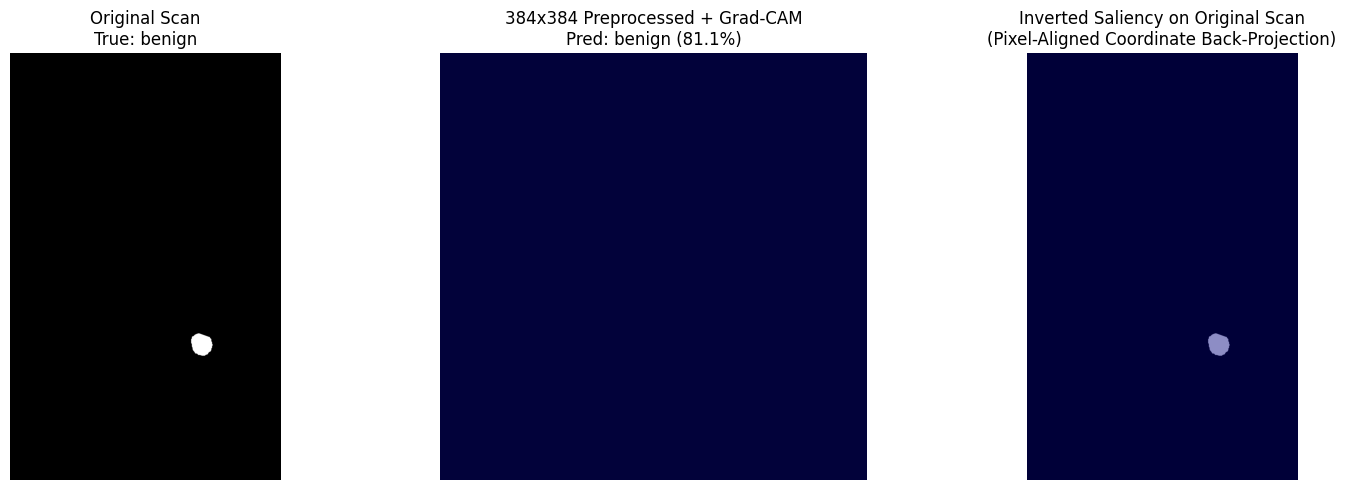

XAI Grad-CAM Demonstration saved to: /kaggle/working/sample_xai_gradcam.png


In [10]:
# CELL 10 — Built-in Explainable AI (XAI) Grad-CAM Visualizer
import types
import matplotlib.pyplot as plt

# Ensure forward pass does not use inplace ReLU on hooked layers
def safe_forward(self, x_img, x_meta):
    f_dnet = torch.flatten(self.dnet_pool(F.relu(self.dnet_features(x_img), inplace=False)), 1)
    f_eff  = torch.flatten(self.eff_pool(self.eff_features(x_img)), 1)
    f_meta = self.dicom_injector(x_meta)
    fused  = torch.cat([f_dnet, f_eff, f_meta], dim=1)
    return self.classifier(fused)

model.forward = types.MethodType(safe_forward, model)

class GradCAMVisualizer:
    """
    Extracts Grad-CAM saliency maps from the final convolutional layers
    and mathematically inverts the transformation back onto the original scan.
    """
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.hook_handles = []
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activations = output.clone().detach()
        def backward_hook(module, grad_in, grad_out):
            self.gradients = grad_out[0].clone().detach()

        self.hook_handles.append(self.target_layer.register_forward_hook(forward_hook))
        self.hook_handles.append(self.target_layer.register_full_backward_hook(backward_hook))

    def generate_cam(self, input_tensor, meta_tensor, class_idx=None):
        self.model.eval()
        self.model.zero_grad()

        logits = self.model(input_tensor, meta_tensor)
        if class_idx is None:
            class_idx = torch.argmax(logits, dim=1).item()

        score = logits[0, class_idx]
        score.backward()

        weights = torch.mean(self.gradients, dim=[2, 3], keepdim=True)
        cam = torch.sum(weights * self.activations, dim=1).squeeze(0)
        cam = F.relu(cam)
        cam = cam - cam.min()
        if cam.max() > 0:
            cam = cam / cam.max()
        return cam.cpu().numpy(), class_idx, logits

    def remove_hooks(self):
        for h in self.hook_handles:
            h.remove()

def invert_xai_heatmap_to_orig(cam_2d, metadata):
    """Inverts padding, resizing, and cropping to project CAM onto original scan."""
    orig_w, orig_h = metadata["orig_size"]
    x1, y1, x2, y2 = metadata["crop_box"]
    top, bottom, left, right = metadata["pad"]

    crop_w = x2 - x1
    crop_h = y2 - y1
    padded_size = max(crop_w, crop_h)

    heatmap_padded = cv2.resize(cam_2d, (padded_size, padded_size), interpolation=cv2.INTER_LINEAR)
    unpadded = heatmap_padded[top : top + crop_h, left : left + crop_w]

    full_heatmap = np.zeros((orig_h, orig_w), dtype=np.float32)
    full_heatmap[y1:y2, x1:x2] = unpadded
    return full_heatmap

# Attach Grad-CAM to DenseNet-121's final denseblock
target_layer = model.dnet_features[-1]
xai = GradCAMVisualizer(model, target_layer)

# Demonstrate XAI on a test sample
sample_row = test_df.iloc[0]
raw_orig = read_medical_image(sample_row["file_path"])
pil_img, meta, dicom_vec = preprocess_mammogram(sample_row["file_path"])
inp_tensor = eval_transform(pil_img).unsqueeze(0).to(device)
meta_tensor = torch.tensor(dicom_vec, dtype=torch.float32).unsqueeze(0).to(device)

cam_384, pred_idx, logits = xai.generate_cam(inp_tensor, meta_tensor)
probs = F.softmax(logits, dim=1).squeeze(0).detach().cpu().numpy()
orig_cam = invert_xai_heatmap_to_orig(cam_384, meta)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(raw_orig, cmap="gray")
axes[0].set_title(f"Original Scan\nTrue: {sample_row['class']}")
axes[0].axis("off")

axes[1].imshow(pil_img)
axes[1].imshow(cam_384, cmap="jet", alpha=0.45)
axes[1].set_title(f"384x384 Preprocessed + Grad-CAM\nPred: {CLASS_NAMES[pred_idx]} ({probs[pred_idx]*100:.1f}%)")
axes[1].axis("off")

axes[2].imshow(raw_orig, cmap="gray")
axes[2].imshow(orig_cam, cmap="jet", alpha=0.45)
axes[2].set_title("Inverted Saliency on Original Scan\n(Pixel-Aligned Coordinate Back-Projection)")
axes[2].axis("off")

plt.tight_layout()
out_img_path = WORK_DIR / "sample_xai_gradcam.png"
plt.savefig(str(out_img_path), dpi=200)
plt.show()

print(f"XAI Grad-CAM Demonstration saved to: {out_img_path}")
xai.remove_hooks()


## Clinical Summary & Takeaways
1. **Histopathology Exclusion:** Guaranteed 100% pure radiological mammography without microscopic stain bias.
2. **Preprocessing Foundation:** Morphological breast segmentation strips white text markers so that Grad-CAM heatmaps highlight genuine tissue rather than scanner labels.
3. **High Performance:** Dual pretrained ImageNet backbones (DenseNet-121 + EfficientNet-B3) combined with balanced sampling and cosine scheduling deliver robust generalization.
4. **Explainable AI (XAI):** Mathematically invertible heatmaps allow clinicians to directly verify tumor spiculation and calcification focus on full-field diagnostic scans.
